# Chapitre 0 — Les maths à la main : du perceptron au MLP

> **Objectif** : comprendre **chaque nombre** qui circule dans un réseau de neurones. Tu vas calculer toi-même, au crayon, un produit scalaire, une étape d'apprentissage du perceptron, une dérivée par la règle de la chaîne, puis une passe avant et une passe arrière complètes dans un petit MLP. Chaque calcul est ensuite **vérifié en NumPy**, et les idées clés sont **animées**. À la fin, une antisèche relie chaque outil mathématique à l'endroit du cours où il sert.

| | |
|---|---|
| **Durée estimée** | 3 h 30 (dont 1 h 30 de calculs à la main) |
| **Prérequis** | aucun, à part les opérations de base et la notion de fonction |
| **Matériel** | papier, crayon, une calculatrice (pour $e^x$ et $\ln$) ; `numpy`, `matplotlib`, `pillow` |
| **Ensuite** | le module 0 reprend tout cela en accéléré et va plus loin (optimiseurs, initialisation, régularisation) |

🧪 **Labo interactif.** Les mêmes calculs sont manipulables dans le [labo du chapitre 0](https://claude.ai/artifact/DVmnXWxXSnQk8DBo5oRjR8) : vecteurs à faire glisser, perceptron pas à pas, rétropropagation étape par étape sur le réseau de la section 8, descente de gradient avec un taux d'apprentissage réglable.

**Comment utiliser ce chapitre.** Les encadrés ✏️ **À toi** posent un calcul. Fais-le **avant** de déplier la solution : c'est l'effort de calcul qui installe l'intuition. La cellule de code qui suit vérifie le résultat.

**Plan**

1. Vecteurs et produit scalaire : ce que « voit » un neurone
2. Matrices : plusieurs neurones d'un coup
3. Le perceptron : apprendre en corrigeant ses erreurs
4. Dérivées : la pente, et comment la calculer
5. La règle de la chaîne : le cœur de la rétropropagation
6. Dérivées partielles, gradient et descente de gradient
7. Exponentielle, logarithme, probabilités : d'où viennent les pertes
8. Un MLP calculé entièrement à la main
9. La forme matricielle, et un MLP qui apprend XOR
10. Antisèche : quel outil mathématique, pour quoi faire
11. Exercices corrigés

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#25241f", "#8a8984"
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})


def show_animation(fig, update, frames, name, fps=6):
    """Render a matplotlib animation to a GIF next to the notebook and display it."""
    anim = FuncAnimation(fig, update, frames=frames)
    path = f"anim_{name}.gif"
    anim.save(path, writer=PillowWriter(fps=fps), dpi=64)
    plt.close(fig)
    display(Image(filename=path))


def sigmoid(z):
    return 1 / (1 + np.exp(-z))

## 1. Vecteurs et produit scalaire : ce que « voit » un neurone

### 💡 Intuition

Un **vecteur** est une liste de nombres : les caractéristiques d'un exemple. Par exemple $x = (3, 1)$ peut décrire un mot par deux scores, ou une protéine par deux propriétés.

Un neurone possède son propre vecteur de **poids** $w$. Il calcule d'abord le **produit scalaire** :
$$
w \cdot x = \sum_{i=1}^{n} w_i\, x_i = w_1x_1 + w_2x_2 + \dots + w_nx_n
$$
On multiplie terme à terme, puis on additionne. Le résultat est un **seul nombre**, qui mesure à quel point $x$ « va dans la même direction » que $w$. Le neurone est un **détecteur de motif** : $w$ est le motif cherché, et $w \cdot x$ dit à quel point l'entrée lui ressemble.

### 📐 La lecture géométrique

$$
w \cdot x = \|w\|\,\|x\|\,\cos\theta, \qquad \|w\| = \sqrt{w \cdot w}
$$
où $\theta$ est l'angle entre les deux vecteurs. Trois cas à retenir :

- $\theta < 90°$ : $\cos\theta > 0$, produit **positif**, les vecteurs « sont d'accord » ;
- $\theta = 90°$ : produit **nul**, les vecteurs sont **orthogonaux** (sans rapport) ;
- $\theta > 90°$ : produit **négatif**, ils s'opposent.

En divisant par les normes, on obtient la **similarité cosinus** $\cos\theta \in [-1, 1]$, qui ne dépend plus de la longueur des vecteurs.

> ✏️ **À toi.** $w = (2, -1)$ et $x = (3, 1)$. Calcule $w \cdot x$, $\|w\|$, $\|x\|$, puis $\cos\theta$ et l'angle $\theta$.

<details><summary>Solution</summary>

- $w \cdot x = 2 \times 3 + (-1) \times 1 = 6 - 1 = 5$
- $\|w\| = \sqrt{4 + 1} = \sqrt 5 \approx 2{,}236$ ; $\|x\| = \sqrt{9 + 1} = \sqrt{10} \approx 3{,}162$
- $\cos\theta = 5 / (\sqrt5\,\sqrt{10}) = 5 / \sqrt{50} \approx 0{,}707$, donc $\theta = 45°$.
</details>

In [2]:
w = np.array([2.0, -1.0])
x = np.array([3.0, 1.0])
dot = w @ x                                     # same as np.dot(w, x) or (w * x).sum()
cos = dot / (np.linalg.norm(w) * np.linalg.norm(x))
print(f"w·x = {dot}, |w| = {np.linalg.norm(w):.3f}, |x| = {np.linalg.norm(x):.3f}, "
      f"cos = {cos:.3f}, angle = {np.degrees(np.arccos(cos)):.1f}°")

w·x = 5.0, |w| = 2.236, |x| = 3.162, cos = 0.707, angle = 45.0°


### 🎬 Animation : le produit scalaire quand $x$ tourne

On garde $w$ fixe et on fait tourner $x$ (de longueur fixe) autour de l'origine. La **projection** de $x$ sur la direction de $w$ (en orange) a pour longueur signée $w \cdot x / \|w\|$ : le produit scalaire est maximal quand $x$ est aligné avec $w$, nul à 90°, minimal à l'opposé.

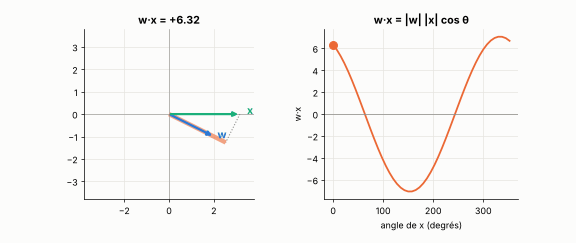

In [3]:
w_dir = w / np.linalg.norm(w)
angles = np.linspace(0, 2 * np.pi, 48, endpoint=False)
r = np.linalg.norm(x)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(9, 3.8))


def update(k):
    a = angles[k]
    xv = r * np.array([np.cos(a), np.sin(a)])
    proj = (xv @ w_dir) * w_dir
    ax.clear()
    ax.axhline(0, color=MUTED, lw=0.6); ax.axvline(0, color=MUTED, lw=0.6)
    ax.annotate("", xy=w, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=PALETTE[0], lw=2.5))
    ax.annotate("", xy=xv, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=PALETTE[2], lw=2.5))
    ax.plot([xv[0], proj[0]], [xv[1], proj[1]], ":", color=MUTED, lw=1.2)
    ax.plot([0, proj[0]], [0, proj[1]], color=PALETTE[1], lw=5, alpha=0.6, solid_capstyle="butt")
    ax.text(*(w * 1.08), "w", color=PALETTE[0], fontsize=12, fontweight="bold")
    ax.text(*(xv * 1.1), "x", color=PALETTE[2], fontsize=12, fontweight="bold")
    ax.set_xlim(-3.8, 3.8); ax.set_ylim(-3.8, 3.8); ax.set_aspect("equal")
    ax.set_title(f"w·x = {w @ xv:+.2f}")
    ax2.clear()
    ax2.plot(np.degrees(angles), [w @ (r * np.array([np.cos(t), np.sin(t)])) for t in angles], color=PALETTE[1])
    ax2.plot(np.degrees(a), w @ xv, "o", color=PALETTE[1], ms=9)
    ax2.axhline(0, color=MUTED, lw=0.8)
    ax2.set_xlabel("angle de x (degrés)"); ax2.set_ylabel("w·x"); ax2.set_title("w·x = |w| |x| cos θ")

fig.subplots_adjust(bottom=0.18, wspace=0.3)
show_animation(fig, update, len(angles), "dot_product")

**Où ça sert dans le cours :**

- **chaque neurone** commence par un produit scalaire (section 3, module 0) ;
- la **similarité cosinus** compare des plongements de mots ou de protéines (modules 3, 11) ;
- l'**attention** d'un Transformer calcule $q \cdot k$ entre chaque paire de positions (module 6) : « à quel point la position $j$ répond-elle à la question posée par la position $i$ ? ».

## 2. Matrices : plusieurs neurones d'un coup

### 💡 Intuition

Une couche contient plusieurs neurones, chacun avec son vecteur de poids. On **empile** ces vecteurs en lignes d'une **matrice** $W$. Le produit matrice-vecteur $Wx$ calcule **tous les produits scalaires d'un coup** : la ligne $i$ de $W$ fait son produit scalaire avec $x$ et donne la sortie $i$.

$$
W x = \begin{pmatrix} \text{— } w_1 \text{ —} \\ \text{— } w_2 \text{ —} \\ \text{— } w_3 \text{ —}\end{pmatrix} x
= \begin{pmatrix} w_1 \cdot x \\ w_2 \cdot x \\ w_3 \cdot x \end{pmatrix}
$$

### 📐 La règle des dimensions (à vérifier systématiquement)

Une matrice de forme $(m \times n)$ fois un vecteur de taille $n$ donne un vecteur de taille $m$. Plus généralement $(m \times n)(n \times p) = (m \times p)$ : **les dimensions intérieures doivent être égales**, et elles « disparaissent ». La moitié des bugs en deep learning sont des erreurs de dimensions ; écrire la forme de chaque objet à côté de chaque ligne est un excellent réflexe.

La **transposée** $W^\top$ échange lignes et colonnes : $(W^\top)_{ij} = W_{ji}$. Elle réapparaîtra dans la passe arrière (section 9), où elle « renvoie » les erreurs vers les entrées.

> ✏️ **À toi.** $W = \begin{pmatrix} 1 & 2 \\ 0 & -1 \\ 3 & 1 \end{pmatrix}$ et $x = (2, 1)$. Quelle est la forme du résultat ? Calcule $Wx$.

<details><summary>Solution</summary>

$W$ est $(3 \times 2)$ et $x$ de taille 2, donc $Wx$ est de taille 3 :
$Wx = (1\cdot2 + 2\cdot1,\ 0\cdot2 + (-1)\cdot1,\ 3\cdot2 + 1\cdot1) = (4, -1, 7)$.
</details>

In [4]:
W = np.array([[1.0, 2.0], [0.0, -1.0], [3.0, 1.0]])
x2 = np.array([2.0, 1.0])
print("W shape", W.shape, "x shape", x2.shape, "-> Wx =", W @ x2, "shape", (W @ x2).shape)
# a batch of B examples stacked as rows of X (B x n): all outputs at once with X @ W.T (B x m)
X = np.array([[2.0, 1.0], [0.0, 1.0], [1.0, -1.0], [3.0, 0.0]])
print("batch:", X.shape, "@", W.T.shape, "=", (X @ W.T).shape)
print(X @ W.T)

W shape (3, 2) x shape (2,) -> Wx = [ 4. -1.  7.] shape (3,)
batch: (4, 2) @ (2, 3) = (4, 3)
[[ 4. -1.  7.]
 [ 2. -1.  1.]
 [-1.  1.  2.]
 [ 3.  0.  9.]]


**Où ça sert :**

- une **couche dense** est $Wx + b$ ; un **mini-batch** est traité d'un coup par $XW^\top$ (module 1) ;
- dans l'attention, $QK^\top$ calcule **tous** les produits scalaires requête-clé en une multiplication (module 6) ;
- **LoRA** remplace une grande mise à jour $\Delta W$ $(d \times d)$ par un produit $BA$ de deux matrices fines $(d \times r)(r \times d)$ : la règle des dimensions dit tout (module 8).

## 3. Le perceptron : apprendre en corrigeant ses erreurs

### 💡 Intuition

Le perceptron (Rosenblatt, 1958) est le neurone le plus simple :
$$
\hat y = \begin{cases} 1 & \text{si } w \cdot x + b > 0 \\ 0 & \text{sinon} \end{cases}
$$
L'ensemble des points où $w \cdot x + b = 0$ est une **droite** (un hyperplan en dimension supérieure) : la **frontière de décision**. $w$ est perpendiculaire à cette droite et pointe vers le côté « 1 » ; le **biais** $b$ la décale.

**La règle d'apprentissage** tient en une ligne : à chaque exemple mal classé, on pousse les poids dans la direction qui corrige l'erreur.
$$
w \leftarrow w + \eta\,(y - \hat y)\,x, \qquad b \leftarrow b + \eta\,(y - \hat y)
$$

- si la prédiction est juste, $y - \hat y = 0$ : rien ne bouge ;
- si on a prédit 0 au lieu de 1, $y - \hat y = +1$ : on **ajoute** $x$ à $w$, ce qui augmente $w \cdot x$ la prochaine fois (car $x \cdot x > 0$) ;
- si on a prédit 1 au lieu de 0, on **retranche** $x$.

### ✏️ À toi : apprendre le ET logique

Données : $(0,0) \to 0$, $(0,1) \to 0$, $(1,0) \to 0$, $(1,1) \to 1$. Départ : $w = (0, 0)$, $b = 0$, $\eta = 1$. Rappel : on prédit 1 seulement si $w \cdot x + b > 0$ (strictement). Parcours les exemples dans l'ordre et remplis le tableau sur deux passages (8 étapes).

<details><summary>Solution (les 8 premières étapes)</summary>

| étape | $x$ | $y$ | $w \cdot x + b$ | $\hat y$ | correction | nouveau $w$ | nouveau $b$ |
|---|---|---|---|---|---|---|---|
| 1 | (0,0) | 0 | 0 | 0 | — | (0, 0) | 0 |
| 2 | (0,1) | 0 | 0 | 0 | — | (0, 0) | 0 |
| 3 | (1,0) | 0 | 0 | 0 | — | (0, 0) | 0 |
| 4 | (1,1) | 1 | 0 | 0 | $+x$ | (1, 1) | 1 |
| 5 | (0,0) | 0 | 1 | 1 | $-x$ | (1, 1) | 0 |
| 6 | (0,1) | 0 | 1 | 1 | $-x$ | (1, 0) | −1 |
| 7 | (1,0) | 0 | 0 | 0 | — | (1, 0) | −1 |
| 8 | (1,1) | 1 | 0 | 0 | $+x$ | (2, 1) | 0 |

À l'étape 5, l'entrée $(0,0)$ ne change pas $w$ (on ajoute un vecteur nul) : seul le biais corrige. C'est le rôle du biais : déplacer la frontière quand les entrées ne le peuvent pas. Le code ci-dessous finit le travail : la convergence arrive au 6ᵉ passage, avec $w = (2, 1)$, $b = -2$.
</details>

In [5]:
X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_and = np.array([0, 0, 0, 1])


def train_perceptron(X, y, epochs=10, lr=1.0, verbose=True):
    w, b, history = np.zeros(X.shape[1]), 0.0, []
    for epoch in range(epochs):
        errors = 0
        for xi, yi in zip(X, y):
            y_hat = int(w @ xi + b > 0)
            if y_hat != yi:
                w, b = w + lr * (yi - y_hat) * xi, b + lr * (yi - y_hat)
                errors += 1
            history.append((w.copy(), b, xi, yi))
        if verbose:
            print(f"pass {epoch + 1}: {errors} error(s), w = {w}, b = {b}")
        if errors == 0:
            break
    return w, b, history

w_p, b_p, hist_p = train_perceptron(X_and, y_and)
print("predictions:", [int(w_p @ xi + b_p > 0) for xi in X_and], "targets:", y_and.tolist())

pass 1: 1 error(s), w = [1. 1.], b = 1.0
pass 2: 3 error(s), w = [2. 1.], b = 0.0
pass 3: 3 error(s), w = [2. 1.], b = -1.0
pass 4: 2 error(s), w = [2. 2.], b = -1.0
pass 5: 1 error(s), w = [2. 1.], b = -2.0
pass 6: 0 error(s), w = [2. 1.], b = -2.0
predictions: [0, 0, 0, 1] targets: [0, 0, 0, 1]


### 🎬 Animation : la frontière se déplace à chaque erreur

Chaque image est une étape. Le point entouré est l'exemple examiné ; la droite est la frontière $w \cdot x + b = 0$, et la zone teintée est le côté « 1 ».

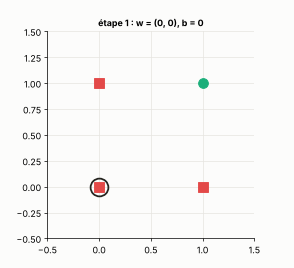

In [6]:
fig, ax = plt.subplots(figsize=(4.6, 4.2))
g = np.linspace(-0.5, 1.5, 200)
GX, GY = np.meshgrid(g, g)


def update(k):
    wk, bk, xi, yi = hist_p[k]
    ax.clear()
    ax.contourf(GX, GY, (wk[0] * GX + wk[1] * GY + bk > 0).astype(float), levels=[-0.5, 0.5, 1.5],
                colors=["#fcfcfb", "#d4e6f8"])
    if abs(wk[1]) > 1e-9:
        ax.plot(g, -(wk[0] * g + bk) / wk[1], color=PALETTE[0], lw=2)
    elif abs(wk[0]) > 1e-9:
        ax.axvline(-bk / wk[0], color=PALETTE[0], lw=2)
    for p, t in zip(X_and, y_and):
        ax.plot(*p, "o" if t else "s", color=PALETTE[2] if t else PALETTE[7], ms=11)
    ax.plot(*xi, "o", mfc="none", mec=INK, ms=20, mew=2)
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5); ax.set_aspect("equal")
    ax.set_title(f"étape {k + 1} : w = ({wk[0]:.0f}, {wk[1]:.0f}), b = {bk:.0f}", fontsize=10)

show_animation(fig, update, len(hist_p), "perceptron_and", fps=3)

### La limite : XOR

Pour le OU exclusif (XOR : $(0,1)$ et $(1,0) \to 1$, $(0,0)$ et $(1,1) \to 0$), **aucune droite** ne sépare les 1 des 0 : les deux classes sont en diagonale. Le perceptron ne converge jamais. Minsky et Papert l'ont montré en 1969, et c'est l'une des raisons du premier « hiver » des réseaux de neurones.

In [7]:
y_xor = np.array([0, 1, 1, 0])
_, _, _ = train_perceptron(X_and, y_xor, epochs=6)

pass 1: 2 error(s), w = [-1.  0.], b = 0.0
pass 2: 3 error(s), w = [-1.  0.], b = 1.0
pass 3: 4 error(s), w = [-1.  0.], b = 1.0
pass 4: 4 error(s), w = [-1.  0.], b = 1.0
pass 5: 4 error(s), w = [-1.  0.], b = 1.0
pass 6: 4 error(s), w = [-1.  0.], b = 1.0


La solution : **empiler** des neurones. Une couche cachée transforme l'espace pour que le problème devienne séparable par une droite (section 9). Mais pour apprendre une couche cachée, la règle du perceptron ne suffit plus. Il faut savoir comment chaque poids influe sur l'erreur finale, et c'est le travail des **dérivées**.

## 4. Dérivées : la pente, et comment la calculer

### 💡 Intuition

La dérivée $f'(x)$ répond à la question : **si je bouge $x$ d'un tout petit peu, de combien bouge $f(x)$ ?**
$$
f(x + h) \approx f(x) + f'(x)\,h \quad \text{pour } h \text{ petit}
$$
Géométriquement, c'est la **pente de la tangente** : la limite des pentes des cordes quand $h \to 0$,
$$
f'(x) = \lim_{h \to 0} \frac{f(x+h) - f(x)}{h}
$$
En apprentissage, $f$ sera la **perte** et $x$ un **poids** : la dérivée dit dans quel sens et avec quelle force tourner chaque bouton.

### 🎬 Animation : de la corde à la tangente

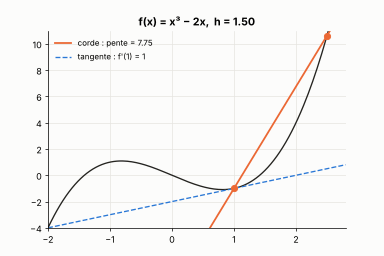

In [8]:
f = lambda t: t ** 3 - 2 * t
df = lambda t: 3 * t ** 2 - 2
x0 = 1.0
hs = np.concatenate([np.linspace(1.5, 0.1, 20), np.full(6, 0.1)])
ts = np.linspace(-2, 2.8, 200)
fig, ax = plt.subplots(figsize=(6, 4))


def update(k):
    h = hs[k]
    slope = (f(x0 + h) - f(x0)) / h
    ax.clear()
    ax.plot(ts, f(ts), color=INK, lw=1.5)
    ax.plot(ts, f(x0) + slope * (ts - x0), color=PALETTE[1], lw=2, label=f"corde : pente = {slope:.2f}")
    ax.plot(ts, f(x0) + df(x0) * (ts - x0), "--", color=PALETTE[0], lw=1.5, label=f"tangente : f'(1) = {df(x0):.0f}")
    ax.plot([x0, x0 + h], [f(x0), f(x0 + h)], "o", color=PALETTE[1], ms=7)
    ax.set_ylim(-4, 11); ax.set_xlim(-2, 2.8); ax.legend(loc="upper left", fontsize=9)
    ax.set_title(f"f(x) = x³ − 2x,  h = {h:.2f}")

show_animation(fig, update, len(hs), "secant_tangent", fps=6)

### 📐 Les règles à connaître (et rien de plus)

| Fonction | Dérivée | Remarque |
|---|---|---|
| $c$ (constante) | $0$ | |
| $x^n$ | $n\,x^{n-1}$ | $x^2 \to 2x$ |
| $e^x$ | $e^x$ | elle est sa propre dérivée |
| $\ln x$ | $1/x$ | |
| $a\,f + b\,g$ | $a\,f' + b\,g'$ | linéarité |
| $f \cdot g$ | $f'g + fg'$ | produit |
| $f(g(x))$ | $f'(g(x))\cdot g'(x)$ | **chaîne** (section 5) |
| $\mathrm{ReLU}(z) = \max(0, z)$ | $1$ si $z > 0$, $0$ sinon | |
| $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ | $\sigma(z)\,(1 - \sigma(z))$ | à dériver ci-dessous |
| $\tanh z$ | $1 - \tanh^2 z$ | exercice 3 |

### ✏️ À toi : la dérivée de la sigmoïde

Écris $\sigma(z) = (1 + e^{-z})^{-1}$ et dérive avec la règle de la chaîne, puis montre que le résultat vaut $\sigma(z)(1 - \sigma(z))$. Calcule ensuite $\sigma(0)$ et $\sigma'(0)$.

<details><summary>Solution</summary>

$\sigma'(z) = -(1 + e^{-z})^{-2} \cdot (-e^{-z}) = \dfrac{e^{-z}}{(1 + e^{-z})^2} = \dfrac{1}{1 + e^{-z}} \cdot \dfrac{e^{-z}}{1 + e^{-z}}$.
Or $\dfrac{e^{-z}}{1 + e^{-z}} = 1 - \dfrac{1}{1 + e^{-z}} = 1 - \sigma(z)$. Donc $\sigma' = \sigma(1 - \sigma)$.
En $z = 0$ : $\sigma(0) = 1/2$ et $\sigma'(0) = 1/4$. C'est le **maximum** de $\sigma'$ : la sigmoïde n'amplifie jamais un signal d'erreur, elle le multiplie au mieux par 0,25. Retiens ce chiffre, il expliquera l'évanouissement du gradient.
</details>

### Vérifier une dérivée : la différence centrée

On ne fait jamais confiance à une dérivée calculée à la main sans la vérifier. La **différence centrée** l'approche numériquement avec une erreur en $O(h^2)$ :
$$
f'(x) \approx \frac{f(x+h) - f(x-h)}{2h}
$$
C'est le **test de gradient** utilisé pour déboguer toute implémentation de rétropropagation.

z = -2.0: sigma'(z) analytic = 0.104994, numerical = 0.104994
z = +0.0: sigma'(z) analytic = 0.250000, numerical = 0.250000
z = +1.5: sigma'(z) analytic = 0.149146, numerical = 0.149146


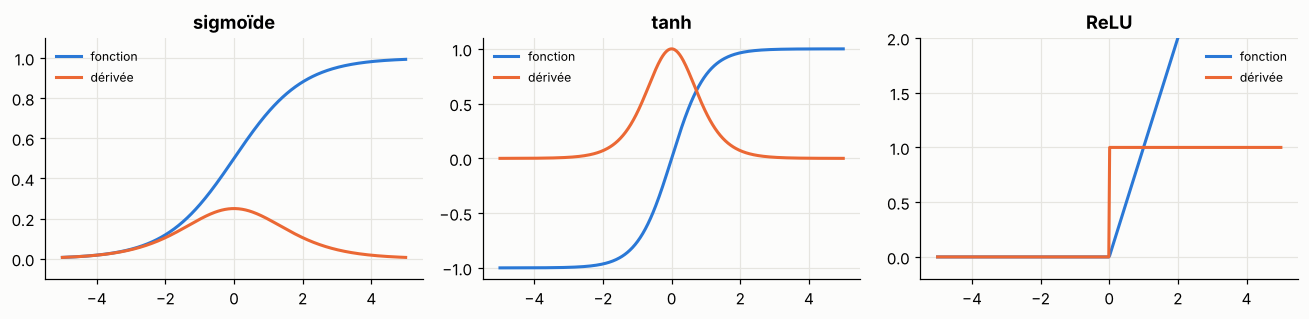

In [9]:
def numerical_derivative(f, x, h=1e-5):
    return (f(x + h) - f(x - h)) / (2 * h)

for z in [-2.0, 0.0, 1.5]:
    analytic = sigmoid(z) * (1 - sigmoid(z))
    print(f"z = {z:+.1f}: sigma'(z) analytic = {analytic:.6f}, numerical = {numerical_derivative(sigmoid, z):.6f}")

zs = np.linspace(-5, 5, 400)
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (name, fn, dfn) in zip(axes, [("sigmoïde", sigmoid, lambda z: sigmoid(z) * (1 - sigmoid(z))),
                                      ("tanh", np.tanh, lambda z: 1 - np.tanh(z) ** 2),
                                      ("ReLU", lambda z: np.maximum(0, z), lambda z: (z > 0).astype(float))]):
    ax.plot(zs, fn(zs), color=PALETTE[0], label="fonction")
    ax.plot(zs, dfn(zs), color=PALETTE[1], label="dérivée")
    ax.set_title(name); ax.legend(fontsize=8)
axes[0].set_ylim(-0.1, 1.1); axes[2].set_ylim(-0.2, 2)
plt.tight_layout(); plt.show()

Lis la courbe orange de chaque panneau : la dérivée de la sigmoïde ne dépasse jamais 0,25 et s'écrase vers 0 dès que $|z| > 4$ (le neurone **sature**) ; celle de tanh monte à 1 ; celle de ReLU vaut exactement 1 du côté positif, d'où sa popularité dans les réseaux profonds, mais exactement 0 du côté négatif (on verra un neurone « mort » en section 8).

## 5. La règle de la chaîne : le cœur de la rétropropagation

### 💡 Intuition : des taux qui se multiplient

Si $u = g(x)$ et $v = f(u)$, alors une petite variation se propage de proche en proche :
$$
dx \;\xrightarrow{\times\, g'(x)}\; du \;\xrightarrow{\times\, f'(u)}\; dv \qquad\Longrightarrow\qquad \frac{dv}{dx} = \frac{dv}{du}\cdot\frac{du}{dx} = f'(g(x))\,g'(x)
$$
Image des **engrenages** : si la roue $u$ tourne 3 fois plus vite que $x$, et $v$ 0,2 fois plus vite que $u$, alors $v$ tourne $3 \times 0{,}2 = 0{,}6$ fois plus vite que $x$. Un réseau de neurones est une longue composition de fonctions ; la dérivée de la perte par rapport à un poids est le **produit des taux** le long du chemin qui relie ce poids à la perte.

### 🎬 Animation : mesurer la chaîne

On prend $u = 3x + 1$ et $v = \sigma(u)$, au point $x = 0$. On pousse $x$ de $dx$ et on mesure les variations réelles $du$ et $dv$. Quand $dx$ rétrécit, le rapport mesuré $dv/dx$ converge vers le produit $f'(u)\cdot g'(x) = \sigma'(1) \times 3 \approx 0{,}197 \times 3 = 0{,}590$.

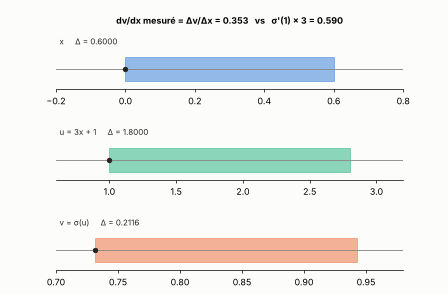

In [10]:
x_c = 0.0
u_c = 3 * x_c + 1
dxs = np.concatenate([np.geomspace(0.6, 0.002, 22), np.full(5, 0.002)])
fig, axes = plt.subplots(3, 1, figsize=(7, 4.6))


def update(k):
    dx = dxs[k]
    du = (3 * (x_c + dx) + 1) - u_c
    dv = sigmoid(u_c + du) - sigmoid(u_c)
    rows = [("x", x_c, dx, -0.2, 0.8, PALETTE[0]), ("u = 3x + 1", u_c, du, 0.6, 3.2, PALETTE[2]),
            ("v = σ(u)", sigmoid(u_c), dv, 0.70, 0.98, PALETTE[1])]
    for ax, (name, base, d, lo, hi, col) in zip(axes, rows):
        ax.clear(); ax.set_xlim(lo, hi); ax.set_ylim(-0.5, 1.0); ax.set_yticks([]); ax.grid(False)
        ax.spines["left"].set_visible(False)
        ax.axhline(0, color=MUTED, lw=1)
        ax.add_patch(plt.Rectangle((base, -0.3), d, 0.6, color=col, alpha=0.5))
        ax.plot(base, 0, "o", color=INK, ms=5)
        ax.text(lo + 0.01 * (hi - lo), 0.62, f"{name}     Δ = {d:.4f}", fontsize=9, color=INK)
    axes[0].set_title(f"dv/dx mesuré = Δv/Δx = {dv / dx:.3f}   vs   σ'(1) × 3 = {sigmoid(1) * (1 - sigmoid(1)) * 3:.3f}", fontsize=10)

fig.subplots_adjust(hspace=0.5, top=0.9, bottom=0.08)
show_animation(fig, update, len(dxs), "chain_rule", fps=5)

### 📐 Le graphe de calcul

On écrit le calcul comme une suite d'opérations élémentaires (un **graphe de calcul**). La passe **avant** calcule les valeurs de gauche à droite. La passe **arrière** part de la perte et calcule, de droite à gauche, la dérivée de la perte par rapport à chaque nœud : chaque nœud reçoit le gradient de la suite et le multiplie par **sa dérivée locale**. C'est tout ce qu'est la **rétropropagation** : la règle de la chaîne appliquée méthodiquement, en réutilisant les produits déjà calculés.

### ✏️ À toi : un neurone à la main

Un neurone sigmoïde avec la perte quadratique : $z = w x + b$, $\hat y = \sigma(z)$, $L = \tfrac12(\hat y - y)^2$.
Valeurs : $x = 2$, $w = 0{,}5$, $b = -0{,}5$, $y = 1$. On donne $\sigma(0{,}5) \approx 0{,}6225$.

1. Passe avant : calcule $z$, $\hat y$, $L$.
2. Passe arrière : calcule $\dfrac{\partial L}{\partial \hat y}$, $\dfrac{\partial \hat y}{\partial z}$, $\dfrac{\partial z}{\partial w}$, puis $\dfrac{\partial L}{\partial w}$ et $\dfrac{\partial L}{\partial b}$.
3. Que fait une étape de descente de gradient avec $\eta = 1$ ?

<details><summary>Solution</summary>

1. $z = 0{,}5 \times 2 - 0{,}5 = 0{,}5$ ; $\hat y = \sigma(0{,}5) \approx 0{,}6225$ ; $L = \tfrac12 (0{,}6225 - 1)^2 = \tfrac12 \times 0{,}1425 \approx 0{,}0713$.
2. $\dfrac{\partial L}{\partial \hat y} = \hat y - y \approx -0{,}3775$ ; $\dfrac{\partial \hat y}{\partial z} = \hat y (1 - \hat y) \approx 0{,}6225 \times 0{,}3775 \approx 0{,}2350$ ; $\dfrac{\partial z}{\partial w} = x = 2$ et $\dfrac{\partial z}{\partial b} = 1$.
   Chaîne : $\dfrac{\partial L}{\partial w} \approx -0{,}3775 \times 0{,}2350 \times 2 \approx -0{,}1774$ ; $\dfrac{\partial L}{\partial b} \approx -0{,}3775 \times 0{,}2350 \approx -0{,}0887$.
3. $w \leftarrow 0{,}5 - 1 \times (-0{,}1774) = 0{,}6774$ et $b \leftarrow -0{,}5 + 0{,}0887 = -0{,}4113$ : les deux augmentent, donc $z$ et $\hat y$ augmentent, et $\hat y$ se rapproche de la cible 1. Le signe négatif du gradient voulait dire : « augmenter ce poids fait **baisser** la perte ».
</details>

In [11]:
x_n, w_n, b_n, y_n = 2.0, 0.5, -0.5, 1.0


def neuron_loss(w, b):
    return 0.5 * (sigmoid(w * x_n + b) - y_n) ** 2

z = w_n * x_n + b_n
y_hat = sigmoid(z)
dL_dyhat, dyhat_dz = y_hat - y_n, y_hat * (1 - y_hat)
dL_dw, dL_db = dL_dyhat * dyhat_dz * x_n, dL_dyhat * dyhat_dz
print(f"forward : z = {z}, y_hat = {y_hat:.4f}, L = {neuron_loss(w_n, b_n):.4f}")
print(f"backward: dL/dyhat = {dL_dyhat:.4f}, dyhat/dz = {dyhat_dz:.4f}, dL/dw = {dL_dw:.4f}, dL/db = {dL_db:.4f}")
print(f"check   : numerical dL/dw = {numerical_derivative(lambda w: neuron_loss(w, b_n), w_n):.4f}, "
      f"dL/db = {numerical_derivative(lambda b: neuron_loss(w_n, b), b_n):.4f}")
print(f"after one step (lr = 1): L = {neuron_loss(w_n - dL_dw, b_n - dL_db):.4f}")

forward : z = 0.5, y_hat = 0.6225, L = 0.0713
backward: dL/dyhat = -0.3775, dyhat/dz = 0.2350, dL/dw = -0.1774, dL/db = -0.0887
check   : numerical dL/dw = -0.1774, dL/db = -0.0887
after one step (lr = 1): L = 0.0392


**Où ça sert :** partout où l'on entraîne quelque chose. PyTorch fait exactement ce calcul quand tu écris `loss.backward()` (module 1), et le module 0 construit un petit moteur d'autodifférentiation qui applique cette règle sur n'importe quel graphe.

## 6. Dérivées partielles, gradient et descente de gradient

### 💡 Intuition

Une perte dépend de **beaucoup** de poids à la fois. La **dérivée partielle** $\partial L / \partial w_i$ mesure l'effet de $w_i$ seul, les autres étant gelés : on dérive par rapport à $w_i$ en traitant les autres comme des constantes. Le **gradient** rassemble toutes les dérivées partielles dans un vecteur :
$$
\nabla L(w) = \left(\frac{\partial L}{\partial w_1}, \dots, \frac{\partial L}{\partial w_n}\right)
$$
Propriété fondamentale : le gradient pointe dans la direction de **plus forte montée** de $L$. Pour descendre, on fait un petit pas dans la direction **opposée** :
$$
w \leftarrow w - \eta\,\nabla L(w)
$$
où $\eta$ est le **taux d'apprentissage** (*learning rate*). Image du randonneur dans le brouillard : il ne voit que la pente sous ses pieds, et fait un pas vers le bas.

### ✏️ À toi

$L(a, b) = a^2 + 3b^2$. Calcule $\nabla L$ au point $(1, 1)$, puis le point obtenu après un pas de descente avec $\eta = 0{,}1$. Que se passe-t-il pour la coordonnée $b$ si $\eta = 0{,}4$ ?

<details><summary>Solution</summary>

$\partial L/\partial a = 2a$ et $\partial L/\partial b = 6b$, donc $\nabla L(1, 1) = (2, 6)$. Après un pas : $(1 - 0{,}2,\ 1 - 0{,}6) = (0{,}8,\ 0{,}4)$. La perte passe de 4 à $0{,}64 + 0{,}48 = 1{,}12$.
Pour $b$, un pas multiplie $b$ par $(1 - 6\eta)$. Avec $\eta = 0{,}4$ : $1 - 2{,}4 = -1{,}4$, donc $|b|$ **grandit** de 40 % à chaque pas en changeant de signe : la descente **diverge**. Elle converge seulement si $|1 - 6\eta| < 1$, c'est-à-dire $\eta < 1/3$. Les directions les plus **courbées** imposent le taux d'apprentissage maximal.
</details>

### 🎬 Animation : trois taux d'apprentissage

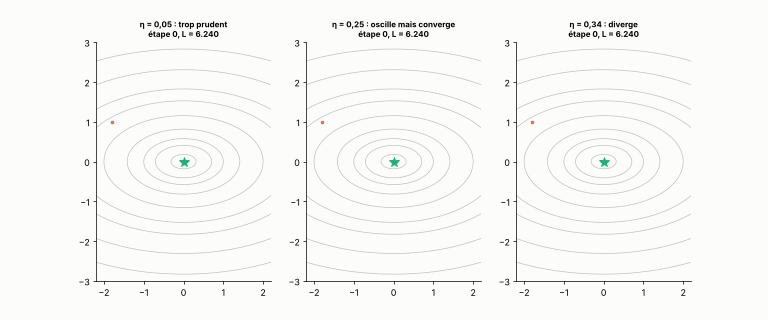

In [12]:
L2 = lambda a, b: a ** 2 + 3 * b ** 2
grad = lambda p: np.array([2 * p[0], 6 * p[1]])
rates = [(0.05, "η = 0,05 : trop prudent"), (0.25, "η = 0,25 : oscille mais converge"), (0.34, "η = 0,34 : diverge")]
paths = []
for lr, _ in rates:
    p = np.array([-1.8, 1.0]); path = [p.copy()]
    for _ in range(25):
        p = p - lr * grad(p); path.append(p.copy())
    paths.append(np.array(path))
A, B = np.meshgrid(np.linspace(-2.2, 2.2, 120), np.linspace(-3, 3, 160))
fig, axes = plt.subplots(1, 3, figsize=(12, 5))


def update(k):
    for ax, path, (lr, title) in zip(axes, paths, rates):
        ax.clear(); ax.grid(False)
        ax.contour(A, B, L2(A, B), levels=[0.1, 0.5, 1, 2, 4, 7, 10, 16, 24], colors="#c3c2b7", linewidths=0.8)
        ax.plot(path[:k + 1, 0], path[:k + 1, 1], "-o", color=PALETTE[1], ms=3, lw=1.2)
        ax.plot(0, 0, "*", color=PALETTE[2], ms=12)
        ax.set_xlim(-2.2, 2.2); ax.set_ylim(-3, 3); ax.set_aspect("equal")
        ax.set_title(f"{title}\nétape {k}, L = {L2(*path[k]):.3f}", fontsize=9)

show_animation(fig, update, 26, "gradient_descent", fps=4)

**Où ça sert :** tous les optimiseurs (SGD, Momentum, Adam : module 0, section 6) sont des variantes de $w \leftarrow w - \eta\,\nabla L$. Le choix du taux d'apprentissage, le *warmup* et la décroissance cosinus (modules 0 et 7) répondent exactement au dilemme de l'animation.

## 7. Exponentielle, logarithme, probabilités : d'où viennent les pertes

### 💡 Trois propriétés qui font tout

1. $e^x > 0$ pour tout $x$ : l'exponentielle transforme n'importe quel score en nombre **positif**, ce qui permet de fabriquer des probabilités.
2. $\ln(ab) = \ln a + \ln b$ : le logarithme transforme les **produits en sommes**. La vraisemblance d'un jeu de données est un produit de probabilités (minuscule, et numériquement instable) ; son logarithme est une somme (stable, et facile à dériver).
3. $\ln$ est croissante : maximiser $p$ ou maximiser $\ln p$, c'est pareil.

### 📐 La softmax : des scores aux probabilités

Pour $K$ classes, un réseau produit $K$ scores $z_1, \dots, z_K$ (les *logits*). La softmax les convertit en probabilités positives qui somment à 1 :
$$
p_i = \frac{e^{z_i}}{\sum_{j=1}^{K} e^{z_j}}
$$

### 📐 L'entropie croisée : le prix de la surprise

Si la bonne classe est $c$, la perte est $L = -\ln p_c$ : nulle si le modèle donne probabilité 1 à la bonne classe, et d'autant plus grande qu'il était **sûr de se tromper** ($-\ln 0{,}01 \approx 4{,}6$). Minimiser l'entropie croisée, c'est maximiser la vraisemblance des données (module 0, section 4).

### ✏️ À toi

Scores $z = (2, 1, 0)$, bonne classe : la première. On donne $e^2 \approx 7{,}389$ et $e^1 \approx 2{,}718$.

1. Calcule les probabilités softmax et la perte.
2. On admet que $\dfrac{\partial L}{\partial z_i} = p_i - y_i$ (avec $y = (1, 0, 0)$). Calcule ce gradient et interprète ses signes.

<details><summary>Solution</summary>

1. Somme $= 7{,}389 + 2{,}718 + 1 = 11{,}107$ ; $p \approx (0{,}665,\ 0{,}245,\ 0{,}090)$ ; $L = -\ln 0{,}665 \approx 0{,}408$.
2. Gradient $\approx (-0{,}335,\ 0{,}245,\ 0{,}090)$. La descente retranche le gradient : le score de la bonne classe **monte** ($-(-0{,}335) > 0$), les deux autres **baissent**, chacun en proportion de la probabilité qu'il volait à tort.
</details>

### 📐 La dérivation de $p_i - y_i$ (à faire une fois dans sa vie)

$L = -\ln p_c = -z_c + \ln \sum_j e^{z_j}$. Dérivons par rapport à $z_i$ :

- le premier terme donne $-1$ si $i = c$, $0$ sinon, c'est-à-dire $-y_i$ ;
- le second donne $\dfrac{e^{z_i}}{\sum_j e^{z_j}} = p_i$ (chaîne : dérivée de $\ln$ fois dérivée de la somme).

D'où $\dfrac{\partial L}{\partial z_i} = p_i - y_i$ : « **prédit moins vrai** ». C'est le gradient le plus important du deep learning : il sort de chaque classifieur, de chaque modèle de langue, à chaque token. Avec deux classes et une sortie sigmoïde, la même dérivation donne $\hat y - y$ (exercice 6).

In [13]:
z_s = np.array([2.0, 1.0, 0.0]); y_s = np.array([1.0, 0.0, 0.0])
p_s = np.exp(z_s) / np.exp(z_s).sum()
ce = lambda z: -np.log(np.exp(z[0]) / np.exp(z).sum())
num_grad = np.array([(ce(z_s + h) - ce(z_s - h)) / 2e-5 for h in np.eye(3) * 1e-5])
print("p =", p_s.round(3), "| L =", round(ce(z_s), 3))
print("p - y         =", (p_s - y_s).round(4))
print("numerical grad=", num_grad.round(4))

p = [0.665 0.245 0.09 ] | L = 0.408
p - y         = [-0.3348  0.2447  0.09  ]
numerical grad= [-0.3348  0.2447  0.09  ]


### Pourquoi l'entropie croisée plutôt que la perte quadratique pour classer ?

Reprends le neurone de la section 5. Avec la perte quadratique, le gradient contient le facteur $\sigma'(z) \le 0{,}25$, qui s'effondre quand le neurone sature. Avec l'entropie croisée, ce facteur **disparaît** : $\partial L / \partial z = \hat y - y$. Un neurone très sûr de lui **et faux** reçoit alors un signal fort, au lieu d'un signal presque nul.

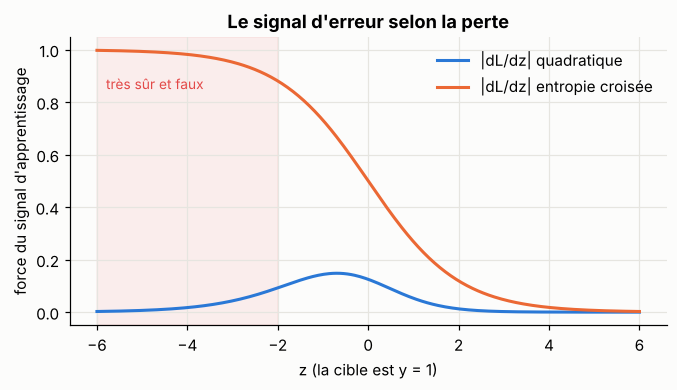

In [14]:
z_grid = np.linspace(-6, 6, 300)
y_true = 1.0
grad_mse = (sigmoid(z_grid) - y_true) * sigmoid(z_grid) * (1 - sigmoid(z_grid))
grad_ce = sigmoid(z_grid) - y_true
plt.figure(figsize=(7, 3.4))
plt.plot(z_grid, np.abs(grad_mse), label="|dL/dz| quadratique")
plt.plot(z_grid, np.abs(grad_ce), label="|dL/dz| entropie croisée")
plt.axvspan(-6, -2, color=PALETTE[7], alpha=0.08)
plt.text(-5.8, 0.85, "très sûr et faux", fontsize=9, color=PALETTE[7])
plt.xlabel("z (la cible est y = 1)"); plt.ylabel("force du signal d'apprentissage"); plt.legend()
plt.title("Le signal d'erreur selon la perte"); plt.show()

Dans la zone rouge (le modèle prédit presque 0 alors que la vérité est 1), la perte quadratique ne transmet presque plus rien, alors que l'entropie croisée transmet un signal proche de 1 : c'est là que le modèle a le plus besoin d'apprendre.

## 8. Un MLP calculé entièrement à la main

On assemble tout. Le réseau a **2 entrées**, **2 neurones cachés** ReLU et **1 sortie** sigmoïde, avec l'entropie croisée binaire comme perte :
$$
z^{(1)} = W^{(1)} x + b^{(1)}, \quad h = \mathrm{ReLU}(z^{(1)}), \quad z^{(2)} = w^{(2)} \cdot h + b^{(2)}, \quad \hat y = \sigma(z^{(2)}), \quad L = -\big[y \ln \hat y + (1-y)\ln(1-\hat y)\big]
$$

Un seul exemple : $x = (1, 2)$, cible $y = 1$. Les poids de départ :
$$
W^{(1)} = \begin{pmatrix} 0{,}5 & -1 \\ 1 & 0{,}5 \end{pmatrix}, \quad b^{(1)} = (0{,}5,\ -1), \quad w^{(2)} = (1,\ -2), \quad b^{(2)} = 0{,}5
$$

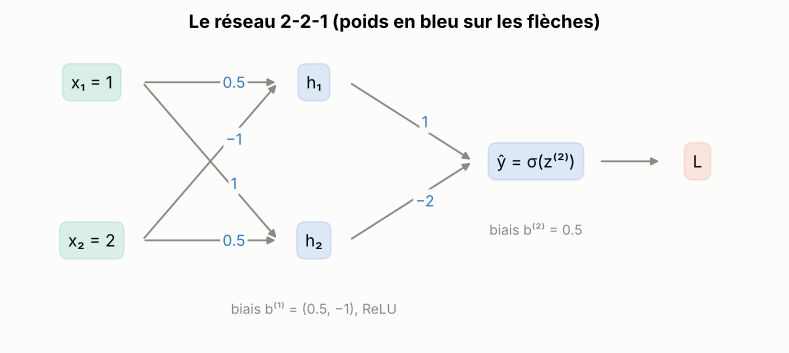

In [15]:
x_m = np.array([1.0, 2.0]); y_m = 1.0
W1 = np.array([[0.5, -1.0], [1.0, 0.5]]); b1 = np.array([0.5, -1.0])
w2 = np.array([1.0, -2.0]); b2 = 0.5

fig, ax = plt.subplots(figsize=(9, 3.6)); ax.axis("off")
nodes = {"x1": (0, 1.6), "x2": (0, 0.2), "h1": (2.2, 1.6), "h2": (2.2, 0.2), "y": (4.4, 0.9), "L": (6.0, 0.9)}
labels = {"x1": "x₁ = 1", "x2": "x₂ = 2", "h1": "h₁", "h2": "h₂", "y": "ŷ = σ(z⁽²⁾)", "L": "L"}
for (a, b_), wgt in {("x1", "h1"): "0.5", ("x2", "h1"): "−1", ("x1", "h2"): "1", ("x2", "h2"): "0.5",
                     ("h1", "y"): "1", ("h2", "y"): "−2", ("y", "L"): ""}.items():
    (x0_, y0_), (x1_, y1_) = nodes[a], nodes[b_]
    half = {"y": 0.62, "x1": 0.5, "x2": 0.5}                     # half-width of the wider boxes
    ax.annotate("", xy=(x1_ - half.get(b_, 0.35), y1_), xytext=(x0_ + half.get(a, 0.35), y0_),
                arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.2))
    if wgt:
        t = 0.64 if a.startswith("x") else 0.5                  # near the receiving neuron: no ambiguity at the crossing
        ax.text(x0_ + t * (x1_ - x0_), y0_ + t * (y1_ - y0_), wgt, fontsize=10, color=PALETTE[0], ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="#fcfcfb", ec="none"))
for n, (px, py) in nodes.items():
    col = PALETTE[2] if n.startswith("x") else PALETTE[1] if n == "L" else PALETTE[0]
    ax.text(px, py, labels[n], ha="center", va="center", fontsize=11,
            bbox=dict(boxstyle="round,pad=0.5", fc=col, alpha=0.15, ec=col))
ax.text(2.2, -0.45, "biais b⁽¹⁾ = (0.5, −1), ReLU", ha="center", fontsize=9, color=MUTED)
ax.text(4.4, 0.25, "biais b⁽²⁾ = 0.5", ha="center", fontsize=9, color=MUTED)
ax.set_xlim(-0.8, 6.8); ax.set_ylim(-0.7, 2.0)
ax.set_title("Le réseau 2-2-1 (poids en bleu sur les flèches)")
plt.show()

### Étape 1 — la passe avant

> ✏️ **À toi.** Calcule $z^{(1)}$, $h$, $z^{(2)}$, $\hat y$ et $L$. On donne $\sigma(-1{,}5) \approx 0{,}1824$ et $\ln 0{,}1824 \approx -1{,}7014$.

<details><summary>Solution</summary>

- $z^{(1)}_1 = 0{,}5 \times 1 + (-1) \times 2 + 0{,}5 = -1$ ; $z^{(1)}_2 = 1 \times 1 + 0{,}5 \times 2 - 1 = 1$
- $h = \mathrm{ReLU}(-1, 1) = (0, 1)$ : le premier neurone caché est **éteint** pour cet exemple
- $z^{(2)} = 1 \times 0 + (-2) \times 1 + 0{,}5 = -1{,}5$ ; $\hat y = \sigma(-1{,}5) \approx 0{,}1824$
- $y = 1$, donc $L = -\ln \hat y \approx 1{,}7014$ : le réseau donne 18 % à la bonne réponse, il se trompe nettement.
</details>

### Étape 2 — la passe arrière, couche par couche

On remonte de la perte vers les entrées. Chaque ligne applique la règle de la chaîne en réutilisant le résultat de la ligne précédente :

| Quantité | Formule | Pourquoi |
|---|---|---|
| $\delta^{(2)} = \partial L / \partial z^{(2)}$ | $\hat y - y$ | sigmoïde + entropie croisée (section 7) |
| $\partial L / \partial w^{(2)}_j$ | $\delta^{(2)}\, h_j$ | $z^{(2)}$ est linéaire en $w^{(2)}_j$, de coefficient $h_j$ |
| $\partial L / \partial b^{(2)}$ | $\delta^{(2)}$ | coefficient 1 |
| $\partial L / \partial h_j$ | $\delta^{(2)}\, w^{(2)}_j$ | $z^{(2)}$ est linéaire en $h_j$, de coefficient $w^{(2)}_j$ |
| $\delta^{(1)}_j = \partial L / \partial z^{(1)}_j$ | $\dfrac{\partial L}{\partial h_j} \cdot \mathrm{ReLU}'(z^{(1)}_j)$ | chaîne à travers l'activation |
| $\partial L / \partial W^{(1)}_{jk}$ | $\delta^{(1)}_j\, x_k$ | même raisonnement que pour $w^{(2)}$ |
| $\partial L / \partial b^{(1)}_j$ | $\delta^{(1)}_j$ | |

> ✏️ **À toi.** Remplis le tableau avec les nombres. Quel est le gradient de tous les poids qui arrivent au premier neurone caché ?

<details><summary>Solution</summary>

- $\delta^{(2)} = 0{,}1824 - 1 = -0{,}8176$
- $\partial L / \partial w^{(2)} = -0{,}8176 \times (0, 1) = (0,\ -0{,}8176)$ ; $\partial L / \partial b^{(2)} = -0{,}8176$
- $\partial L / \partial h = -0{,}8176 \times (1, -2) = (-0{,}8176,\ 1{,}6351)$
- $\mathrm{ReLU}'(z^{(1)}) = (0, 1)$ car $z^{(1)} = (-1, 1)$, donc $\delta^{(1)} = (0,\ 1{,}6351)$
- $\partial L / \partial W^{(1)} = \begin{pmatrix} 0 & 0 \\ 1{,}6351 & 3{,}2703 \end{pmatrix}$ (ligne $j$ : $\delta^{(1)}_j \times x$) ; $\partial L / \partial b^{(1)} = (0,\ 1{,}6351)$

Tous les poids du premier neurone caché ont un gradient **nul** : ce neurone était éteint ($z^{(1)}_1 < 0$), la ReLU bloque le signal. Si un neurone ReLU est éteint pour **tous** les exemples, il n'apprend plus jamais : c'est un **neurone mort**.
</details>

### Étape 3 — la mise à jour, et la vérification

Avec $\eta = 0{,}1$, chaque paramètre devient $\theta - 0{,}1 \times \partial L / \partial \theta$.

> ✏️ **À toi.** Calcule les nouveaux $w^{(2)}$, $b^{(2)}$, la nouvelle deuxième ligne de $W^{(1)}$ et le nouveau $b^{(1)}_2$. Refais la passe avant : la perte a-t-elle baissé ?

<details><summary>Solution</summary>

- $w^{(2)} = (1,\ -2 + 0{,}0818) = (1,\ -1{,}9182)$ ; $b^{(2)} = 0{,}5 + 0{,}0818 = 0{,}5818$
- ligne 2 de $W^{(1)}$ : $(1 - 0{,}1635,\ 0{,}5 - 0{,}3270) = (0{,}8365,\ 0{,}1730)$ ; $b^{(1)}_2 = -1 - 0{,}1635 = -1{,}1635$
- nouvelle passe avant : $z^{(1)}_2 = 0{,}8365 + 0{,}1730 \times 2 - 1{,}1635 \approx 0{,}019$, donc $h \approx (0,\ 0{,}019)$ ; $z^{(2)} \approx -1{,}9182 \times 0{,}019 + 0{,}5818 \approx 0{,}545$ ; $\hat y \approx 0{,}633$ ; $L \approx 0{,}457$.

La perte passe de 1,70 à 0,46 en une étape. Mais regarde **comment** : le réseau a presque éteint le deuxième neurone caché (de $h_2 = 1$ à $0{,}019$), parce qu'il était relié à la sortie par un poids négatif (−2) qui tirait $\hat y$ vers le bas. Il a surtout corrigé le **biais de sortie**. La descente de gradient prend le chemin le plus raide **localement**, pas forcément le plus « intelligent ».
</details>

In [16]:
def forward(params, x):
    W1, b1, w2, b2 = params
    z1 = W1 @ x + b1
    h = np.maximum(0, z1)
    z2 = w2 @ h + b2
    return z1, h, z2, sigmoid(z2)


def bce(y_hat, y):
    return -(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))


def backward(params, x, y):
    W1, b1, w2, b2 = params
    z1, h, z2, y_hat = forward(params, x)
    d2 = y_hat - y                          # dL/dz2
    dw2, db2 = d2 * h, d2
    dh = d2 * w2                            # dL/dh
    d1 = dh * (z1 > 0)                      # dL/dz1 (ReLU derivative)
    dW1, db1 = np.outer(d1, x), d1          # row j = d1[j] * x
    return [dW1, db1, dw2, db2]

params = [W1, b1, w2, b2]
z1, h, z2, y_hat = forward(params, x_m)
print(f"forward : z1 = {z1}, h = {h}, z2 = {z2}, y_hat = {y_hat:.4f}, L = {bce(y_hat, y_m):.4f}")
grads = backward(params, x_m, y_m)
for name, g in zip(["dW1", "db1", "dw2", "db2"], grads):
    print(f"{name} =", (np.round(g, 4) + 0.0).tolist())          # + 0.0 turns -0.0 into 0.0

# gradient check: perturb every parameter, one at a time
flat_numeric = []
for i, p in enumerate(params):
    p_arr = np.atleast_1d(np.array(p, dtype=float))
    num = np.zeros_like(p_arr)
    for idx in np.ndindex(p_arr.shape):
        for sign in (+1, -1):
            q = p_arr.copy(); q[idx] += sign * 1e-5
            new = [np.array(pp, dtype=float) for pp in params]
            new[i] = q if np.ndim(p) else float(q[0])
            num[idx] += sign * bce(forward(new, x_m)[3], y_m) / 2e-5
    flat_numeric.append(np.abs(num - np.atleast_1d(grads[i])).max())
print("max |analytic - numerical| per parameter group:", [f"{e:.1e}" for e in flat_numeric])

lr = 0.1
new_params = [p - lr * g for p, g in zip(params, grads)]
_, h_new, z2_new, y_new = forward(new_params, x_m)
print(f"after one step: h = {np.round(h_new, 4)}, z2 = {z2_new:.4f}, y_hat = {y_new:.4f}, L = {bce(y_new, y_m):.4f}")

forward : z1 = [-1.  1.], h = [0. 1.], z2 = -1.5, y_hat = 0.1824, L = 1.7014
dW1 = [[0.0, 0.0], [1.6351, 3.2703]]
db1 = [0.0, 1.6351]
dw2 = [0.0, -0.8176]
db2 = -0.8176
max |analytic - numerical| per parameter group: ['8.7e-11', '2.1e-11', '3.8e-12', '3.8e-12']
after one step: h = [0.     0.0189], z2 = 0.5455, y_hat = 0.6331, L = 0.4571


L'écart entre gradients analytiques et numériques est de l'ordre de $10^{-10}$ : nos calculs à la main sont justes. Garde ce **test de gradient** sous le coude ; c'est le premier réflexe quand tu écris une couche à la main.

## 9. La forme matricielle, et un MLP qui apprend XOR

### 📐 Les quatre équations de la rétropropagation

Pour une couche $\ell$ : $z^{(\ell)} = W^{(\ell)} a^{(\ell-1)} + b^{(\ell)}$ et $a^{(\ell)} = \varphi(z^{(\ell)})$, avec $a^{(0)} = x$. En notant $\delta^{(\ell)} = \partial L / \partial z^{(\ell)}$ et $\odot$ le produit terme à terme :

$$
\begin{aligned}
&(1)\quad \delta^{(\text{sortie})} = \hat y - y && \text{(sigmoïde ou softmax + entropie croisée)}\\
&(2)\quad \frac{\partial L}{\partial W^{(\ell)}} = \delta^{(\ell)}\, \big(a^{(\ell-1)}\big)^{\!\top} && \text{(un produit extérieur : même forme que } W^{(\ell)}\text{)}\\
&(3)\quad \frac{\partial L}{\partial b^{(\ell)}} = \delta^{(\ell)}\\
&(4)\quad \delta^{(\ell-1)} = \Big(\big(W^{(\ell)}\big)^{\!\top} \delta^{(\ell)}\Big) \odot \varphi'\big(z^{(\ell-1)}\big) && \text{(la transposée renvoie l'erreur vers l'arrière)}
\end{aligned}
$$

C'est exactement ce que tu as fait à la main en section 8, écrit pour toutes les tailles. Pour un **mini-batch** de $B$ exemples empilés en lignes, (2) devient $\frac{1}{B}\Delta^\top A$, une moyenne de produits extérieurs.

| Objet | Forme | Moyen mnémotechnique |
|---|---|---|
| $W^{(\ell)}$ | $(n_\ell \times n_{\ell-1})$ | « sortie × entrée » |
| $a^{(\ell-1)}$ | $(n_{\ell-1})$ | |
| $\delta^{(\ell)}$ | $(n_\ell)$ | même forme que $z^{(\ell)}$ |
| $\partial L / \partial W^{(\ell)}$ | $(n_\ell \times n_{\ell-1})$ | **toujours la même forme que le paramètre** |

### 🎬 Animation : un MLP 2-4-1 apprend XOR

Le perceptron échouait sur XOR. Avec une couche cachée de 4 neurones tanh, entraînée par les quatre équations ci-dessus (descente de gradient sur les 4 exemples), le réseau courbe sa frontière jusqu'à séparer les diagonales.

final loss 0.0015, predictions [0.    0.998 0.998 0.002], targets [0. 1. 1. 0.]


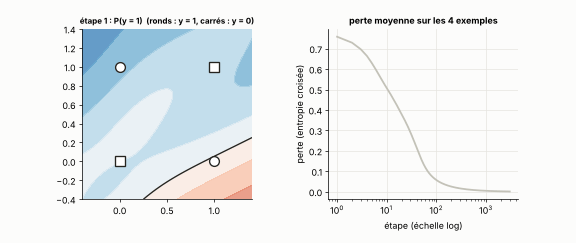

In [17]:
rng = np.random.default_rng(3)
X_x = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
Y_x = np.array([0, 1, 1, 0], dtype=float)
P = {"W1": rng.normal(0, 1, (4, 2)), "b1": np.zeros(4), "W2": rng.normal(0, 1, (1, 4)), "b2": np.zeros(1)}


def mlp_forward(P, X):
    Z1 = X @ P["W1"].T + P["b1"]            # (B, 4)
    A1 = np.tanh(Z1)
    Z2 = A1 @ P["W2"].T + P["b2"]           # (B, 1)
    return Z1, A1, sigmoid(Z2)[:, 0]


def mlp_step(P, X, Y, lr):
    B = len(X)
    Z1, A1, Yh = mlp_forward(P, X)
    D2 = (Yh - Y)[:, None]                  # (1) output delta, (B, 1)
    gW2, gb2 = D2.T @ A1 / B, D2.mean(0)    # (2), (3)
    D1 = (D2 @ P["W2"]) * (1 - A1 ** 2)     # (4) tanh' = 1 - tanh^2, (B, 4)
    gW1, gb1 = D1.T @ X / B, D1.mean(0)
    for k, g in zip(["W1", "b1", "W2", "b2"], [gW1, gb1, gW2, gb2]):
        P[k] -= lr * g
    return float(bce(Yh, Y).mean())

snapshots, losses = [], []
keep = set(np.unique(np.geomspace(1, 3000, 40).astype(int)))
for step in range(1, 3001):
    losses.append(mlp_step(P, X_x, Y_x, lr=0.5))
    if step in keep:
        snapshots.append((step, {k: v.copy() for k, v in P.items()}))
print(f"final loss {losses[-1]:.4f}, predictions {np.round(mlp_forward(P, X_x)[2], 3)}, targets {Y_x}")

G = np.linspace(-0.4, 1.4, 120)
GX, GY = np.meshgrid(G, G)
grid = np.c_[GX.ravel(), GY.ravel()]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(9, 3.8))


def update(k):
    step, Pk = snapshots[k]
    prob = mlp_forward(Pk, grid)[2].reshape(GX.shape)
    ax.clear(); ax.grid(False)
    ax.contourf(GX, GY, prob, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.75)
    ax.contour(GX, GY, prob, levels=[0.5], colors=INK, linewidths=1.5)
    for p, t in zip(X_x, Y_x):
        ax.plot(*p, "o" if t else "s", color="white", mec=INK, ms=11, mew=1.5)
    ax.set_aspect("equal"); ax.set_title(f"étape {step} : P(y = 1)  (ronds : y = 1, carrés : y = 0)", fontsize=9)
    ax2.clear()
    ax2.plot(np.arange(1, len(losses) + 1), losses, color="#c3c2b7")
    ax2.plot(np.arange(1, step + 1), losses[:step], color=PALETTE[1])
    ax2.set_xscale("log"); ax2.set_xlabel("étape (échelle log)"); ax2.set_ylabel("perte (entropie croisée)")
    ax2.set_title("perte moyenne sur les 4 exemples", fontsize=10)

fig.subplots_adjust(bottom=0.18, wspace=0.35)
show_animation(fig, update, len(snapshots), "mlp_xor", fps=5)

Que fait la couche cachée ? Elle **déforme l'espace** : dans l'espace des 4 activations cachées, les points de XOR deviennent séparables par un simple hyperplan, et la sortie (un neurone sigmoïde, donc un « perceptron doux ») fait le reste. C'est l'idée centrale de tout le deep learning : apprendre une **représentation** où le problème devient simple.

## 10. Antisèche : quel outil mathématique, pour quoi faire

| Outil | Formule clé | Où il sert dans le cours |
|---|---|---|
| Produit scalaire | $w \cdot x = \sum_i w_i x_i = \lVert w\rVert\lVert x\rVert\cos\theta$ | chaque neurone ; attention $q \cdot k$ (m06) ; similarité cosinus (m03, m11, m16) |
| Produit matriciel | $(m \times n)(n \times p) = (m \times p)$ | couches denses, mini-batches (m01) ; $QK^\top$ (m06) ; LoRA $BA$ (m08) |
| Transposée | $(W^\top)_{ij} = W_{ji}$ | passe arrière : $W^\top \delta$ |
| Dérivée | $f(x+h) \approx f(x) + f'(x)h$ | sensibilité de la perte à un poids |
| Règle de la chaîne | $(f \circ g)' = f'(g)\,g'$ | rétropropagation, autograd (m00, m01) ; gradients qui s'évanouissent (m04) |
| Gradient | $\nabla L = (\partial L/\partial w_i)_i$ | descente de gradient, Adam (m00) |
| Exponentielle | $e^x > 0$ | softmax (classification, attention, modèles de langue) |
| Logarithme | $\ln(ab) = \ln a + \ln b$ | log-vraisemblance, entropie croisée, perplexité (m02, m04, m07) |
| Probabilités | $\sum_i p_i = 1$ | sorties des classifieurs ; MLM des PLM (m09) ; DPO (m14) |
| Moyenne, variance | $\mathrm{Var}(\sum_i w_i x_i) = n\,\mathrm{Var}(w)\mathrm{Var}(x)$ | initialisation, normalisation (m00, m06) |
| Produit terme à terme | $a \odot b$ | dérivée des activations dans la passe arrière, masques (m01) |

Le module 0 reprend ces outils à grande vitesse et les complète : optimiseurs (Momentum, Adam), initialisation, régularisation, et un moteur d'autodifférentiation de 60 lignes.

## 11. Exercices corrigés

**Exercice 1 — similarité cosinus.** $a = (1, 2, 2)$ et $b = (2, 0, 1)$. Calcule $a \cdot b$, $\cos\theta$, et un vecteur non nul orthogonal à $a$.

<details><summary>Solution</summary>

$a \cdot b = 2 + 0 + 2 = 4$ ; $\lVert a \rVert = 3$, $\lVert b \rVert = \sqrt5$ ; $\cos\theta = 4 / (3\sqrt5) \approx 0{,}596$. Un vecteur orthogonal à $a$ : $(2, -1, 0)$, car $2 - 2 + 0 = 0$ (il y en a une infinité, tout un plan).
</details>

**Exercice 2 — le perceptron du OU.** Données : $(0,0) \to 0$, les trois autres $\to 1$. Départ $w = (0, 0)$, $b = 0$, $\eta = 1$, même règle qu'en section 3. Déroule les étapes jusqu'à convergence.

<details><summary>Solution</summary>

Passage 1 : (0,0) correct ; (0,1) prédit 0 au lieu de 1, donc $w = (0, 1)$, $b = 1$ ; (1,0) donne $0 + 1 = 1 > 0$, correct ; (1,1) correct.
Passage 2 : (0,0) donne $b = 1 > 0$, prédit 1 au lieu de 0, donc $b = 0$ ($w$ inchangé) ; (0,1) donne 1, correct ; (1,0) donne 0, prédit 0 au lieu de 1, donc $w = (1, 1)$, $b = 1$ ; (1,1) correct.
Passage 3 : (0,0) donne $1 > 0$, faux, donc $b = 0$ ; les trois autres sont corrects ($1, 1, 2 > 0$).
Passage 4 : aucune erreur. Solution : $w = (1, 1)$, $b = 0$, frontière $x_1 + x_2 = 0$, qui laisse $(0,0)$ juste **sur** la droite, du côté 0 grâce à l'inégalité stricte.
</details>

**Exercice 3 — la dérivée de tanh.** Avec $\tanh z = \dfrac{e^z - e^{-z}}{e^z + e^{-z}}$, montre que $\tanh'(z) = 1 - \tanh^2 z$.

<details><summary>Solution</summary>

Règle du quotient : $\tanh' = \dfrac{(e^z + e^{-z})^2 - (e^z - e^{-z})^2}{(e^z + e^{-z})^2} = 1 - \left(\dfrac{e^z - e^{-z}}{e^z + e^{-z}}\right)^2 = 1 - \tanh^2 z$.
</details>

**Exercice 4 — la chaîne à trois maillons.** Calcule $\dfrac{d}{dw}\ln\!\big(1 + e^{wx}\big)$, puis sa valeur pour $w = 0$, $x = 3$.

<details><summary>Solution</summary>

Trois maillons : $u = wx$, $v = 1 + e^u$, $f = \ln v$. Donc $\dfrac{df}{dw} = \dfrac{1}{v} \cdot e^u \cdot x = x\,\dfrac{e^{wx}}{1 + e^{wx}} = x\,\sigma(wx)$. En $w = 0$ : $3 \times \sigma(0) = 1{,}5$. (Cette fonction, la *softplus*, est une version lisse de ReLU, et sa dérivée est la sigmoïde.)
</details>

**Exercice 5 — le MLP de la section 8 avec des neurones cachés sigmoïdes.** Même réseau, mêmes poids, même exemple, mais $h = \sigma(z^{(1)})$. Calcule la passe avant, $\delta^{(2)}$, $\partial L/\partial w^{(2)}$, $\delta^{(1)}$ et $\partial L/\partial W^{(1)}$. Données : $\sigma(-1) \approx 0{,}2689$, $\sigma(1) \approx 0{,}7311$, $\sigma(-0{,}6932) \approx 0{,}3333$.

<details><summary>Solution</summary>

- $z^{(1)} = (-1, 1)$, $h \approx (0{,}2689,\ 0{,}7311)$ ; $z^{(2)} \approx 0{,}2689 - 1{,}4622 + 0{,}5 = -0{,}6932$ ; $\hat y \approx 0{,}3333$ ; $L = -\ln(1/3) \approx 1{,}0986$.
- $\delta^{(2)} \approx -0{,}6667$ ; $\partial L / \partial w^{(2)} = \delta^{(2)} h \approx (-0{,}1793,\ -0{,}4874)$.
- $\partial L / \partial h = \delta^{(2)} w^{(2)} \approx (-0{,}6667,\ 1{,}3333)$ ; $\sigma'(z^{(1)}) = h(1-h) \approx (0{,}1966,\ 0{,}1966)$ ; $\delta^{(1)} \approx (-0{,}1311,\ 0{,}2622)$.
- $\partial L / \partial W^{(1)} = \delta^{(1)} x^\top \approx \begin{pmatrix} -0{,}1311 & -0{,}2622 \\ 0{,}2622 & 0{,}5243 \end{pmatrix}$.

Compare avec la ReLU : ici le premier neurone n'est plus éteint (il reçoit un gradient), mais chaque signal est **divisé par 5** environ en traversant la sigmoïde ($\sigma' \approx 0{,}197$). Empile 10 couches comme ça et le signal est divisé par $5^{10} \approx 10^7$ : c'est l'**évanouissement du gradient**, la raison pour laquelle les réseaux profonds utilisent ReLU, GELU ou SiLU, avec des connexions résiduelles (module 6).
</details>

**Exercice 6 — deux classes : softmax ou sigmoïde ?** Montre qu'une softmax à deux scores $(z_1, z_0)$ donne $p_1 = \sigma(z_1 - z_0)$. Qu'en déduis-tu pour la sortie d'un classifieur binaire ?

<details><summary>Solution</summary>

$p_1 = \dfrac{e^{z_1}}{e^{z_1} + e^{z_0}} = \dfrac{1}{1 + e^{-(z_1 - z_0)}} = \sigma(z_1 - z_0)$. Seule la **différence** des scores compte : un seul score $z = z_1 - z_0$ suffit, avec une sigmoïde. Les deux formulations sont équivalentes, et la dérivation de la section 7 redonne $\partial L / \partial z = \hat y - y$.
</details>

In [18]:
# Verify exercise 5 numerically
def forward_sig(params, x):
    W1, b1, w2, b2 = params
    z1 = W1 @ x + b1
    h = sigmoid(z1)
    return z1, h, w2 @ h + b2, sigmoid(w2 @ h + b2)

z1, h, z2, y_hat = forward_sig(params, x_m)
d2 = y_hat - y_m
d1 = d2 * w2 * h * (1 - h)
print(f"h = {h.round(4)}, z2 = {z2:.4f}, y_hat = {y_hat:.4f}, L = {bce(y_hat, y_m):.4f}")
print("dL/dw2 =", (d2 * h).round(4), "| delta1 =", d1.round(4))
print("dL/dW1 =\n", np.outer(d1, x_m).round(4))

h = [0.2689 0.7311], z2 = -0.6932, y_hat = 0.3333, L = 1.0986
dL/dw2 = [-0.1793 -0.4874] | delta1 = [-0.1311  0.2622]
dL/dW1 =
 [[-0.1311 -0.2622]
 [ 0.2622  0.5243]]


---

**Et maintenant ?** Tu sais ce qui se passe à chaque étape d'un réseau. Le **module 0** reprend ces idées en accéléré et les complète : optimiseurs (Momentum, RMSProp, Adam), initialisation, régularisation, un moteur d'autodifférentiation, puis un MLP complet en NumPy et le passage à PyTorch.